In [20]:
# Building a Demand Forecasting Model
# Importing the required libraries


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
# Loading Amazon sales dataset with quote ignoring to handle malformed trailing records
# Displaying first five rows of dataset
import csv

try:
    # Using quoting=csv.QUOTE_NONE (3) to prevent unmatched quotes from causing EOF errors
    df = pd.read_csv("/content/Amazon Sale Report.csv", quoting=csv.QUOTE_NONE, on_bad_lines='skip')
except Exception as e:
    print(f"Initial parse failed: {e}")
    # Alternative fallback if columns are misaligned due to unquoted structures
    df = pd.read_csv("/content/Amazon Sale Report.csv", engine='python', on_bad_lines='skip')

df.head()

/tmp/ipykernel_2824/2529093324.py:7: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/Amazon Sale Report.csv", quoting=csv.QUOTE_NONE, on_bad_lines='skip')


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
2,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
3,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN
4,5,404-1490984-4578765,04-30-22,Shipped,Amazon,Amazon.in,Expedited,SET264,SET264-KR-NP-XL,Set,...,INR,824.00,GHAZIABAD,UTTAR PRADESH,201102.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,NaN


In [22]:
# Checking the number of rows and columns
print(df.shape)

# Displaying all column names
print(df.columns)

# Checking dataset information and data types
df.info()

# Checking missing values in each column
df.isnull().sum()

(58704, 24)
Index(['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ',
       'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN',
       'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city',
       'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids',
       'B2B', 'fulfilled-by', 'Unnamed: 22'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58704 entries, 0 to 58703
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               58704 non-null  int64  
 1   Order ID            58704 non-null  object 
 2   Date                58704 non-null  object 
 3   Status              58704 non-null  object 
 4   Fulfilment          58704 non-null  object 
 5   Sales Channel       58704 non-null  object 
 6   ship-service-level  58704 non-null  object 
 7   Style               58704 non-null  object 
 8   SKU                 5870

,0
index,0
Order ID,0
Date,0
Status,0
Fulfilment,0
Sales Channel,0
ship-service-level,0
Style,0
SKU,0
Category,0


In [23]:
# Removing duplicate records
df = df.drop_duplicates()

# Converting Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'], format='%m-%d-%y', errors='coerce')

# Converting Qty column into numeric format
df['Qty'] = pd.to_numeric(df['Qty'], errors='coerce')

# Removing rows with missing Date or Qty values
df = df.dropna(subset=['Date', 'Qty'])

# Removing negative demand values
df = df[df['Qty'] >= 0]

# Displaying cleaned dataset
df.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
2,3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
3,4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN
4,5,404-1490984-4578765,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,SET264,SET264-KR-NP-XL,Set,...,INR,824.00,GHAZIABAD,UTTAR PRADESH,201102.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,NaN


In [24]:
# Grouping sales data by date and calculating total daily demand
daily = df.groupby('Date')['Qty'].sum().reset_index()

# Renaming columns for better understanding
daily.columns = ['Date', 'Demand']

# Sorting data according to date
daily = daily.sort_values('Date')

# Displaying daily demand dataset
daily.head()

,Date,Demand
0,2022-03-31,139
1,2022-04-01,1038
2,2022-04-02,1146
3,2022-04-03,1196
4,2022-04-04,1005


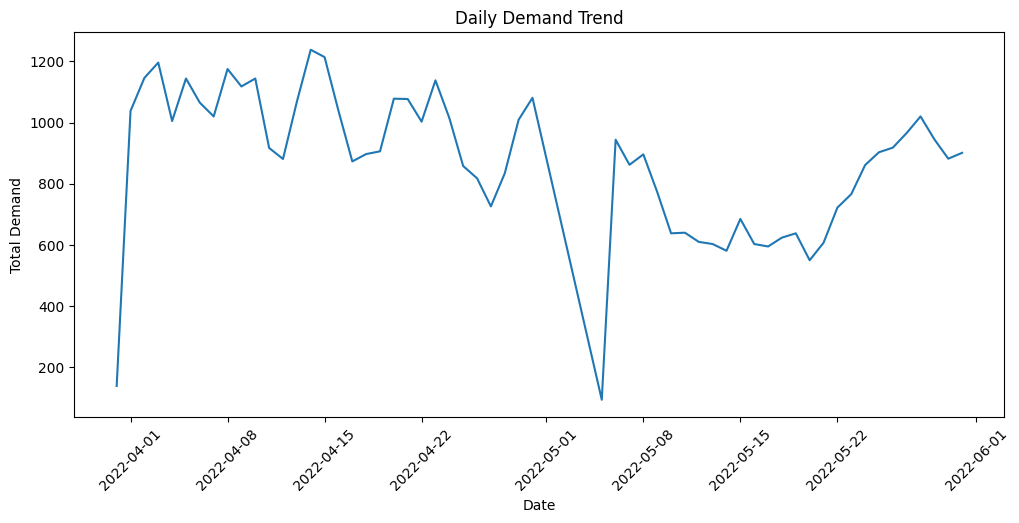

In [25]:
# Visualizing daily demand trend

plt.figure(figsize=(12,5))

plt.plot(daily['Date'], daily['Demand'])

plt.title('Daily Demand Trend')
plt.xlabel('Date')
plt.ylabel('Total Demand')

plt.xticks(rotation=45)
plt.show()

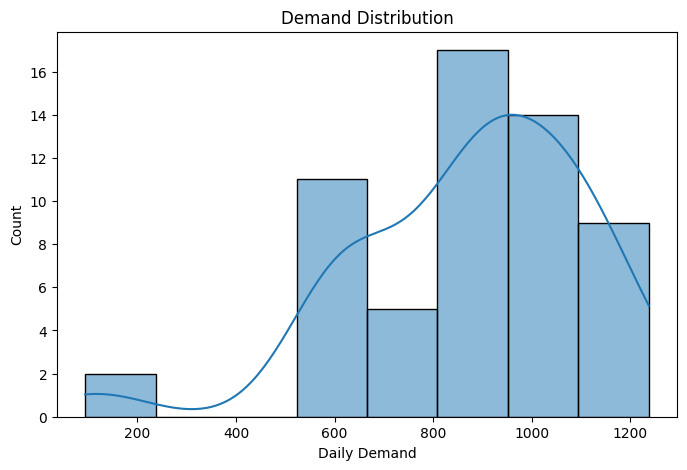

In [26]:
# Visualizing distribution of daily demand

plt.figure(figsize=(8,5))

sns.histplot(daily['Demand'], kde=True)

plt.title('Demand Distribution')
plt.xlabel('Daily Demand')

plt.show()

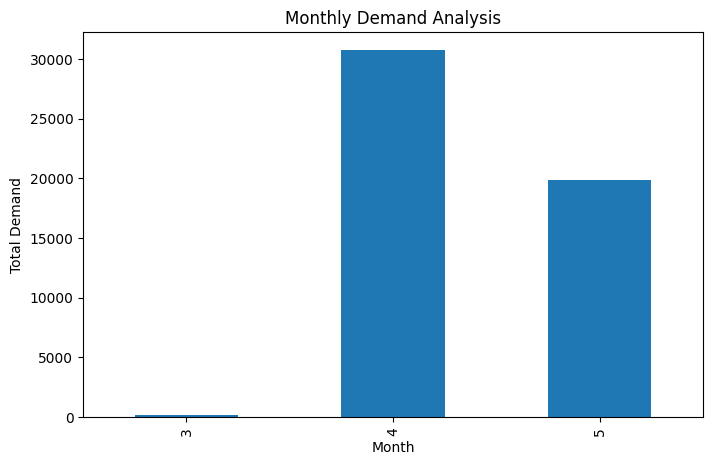

In [27]:
# Extracting month from date
daily['Month'] = daily['Date'].dt.month

# Calculating total demand for each month
monthly = daily.groupby('Month')['Demand'].sum()

# Visualizing monthly demand
plt.figure(figsize=(8,5))

monthly.plot(kind='bar')

plt.title('Monthly Demand Analysis')
plt.xlabel('Month')
plt.ylabel('Total Demand')

plt.show()

In [28]:
# Extracting date-related features
daily['Day'] = daily['Date'].dt.day
daily['Weekday'] = daily['Date'].dt.dayofweek
daily['Month'] = daily['Date'].dt.month

# Creating lag features using previous demand values
daily['Lag1'] = daily['Demand'].shift(1)
daily['Lag2'] = daily['Demand'].shift(2)
daily['Lag7'] = daily['Demand'].shift(7)

# Calculating 7-day rolling average demand
daily['Rolling_Mean'] = daily['Demand'].shift(1).rolling(7).mean()

# Removing rows containing missing values
daily = daily.dropna()

# Displaying updated dataset
daily.head()

,Date,Demand,Month,Day,Weekday,Lag1,Lag2,Lag7,Rolling_Mean
7,2022-04-07,1020,4,7,3,1065.0,1144.0,139.0,961.857143
8,2022-04-08,1175,4,8,4,1020.0,1065.0,1038.0,1087.714286
9,2022-04-09,1118,4,9,5,1175.0,1020.0,1146.0,1107.285714
10,2022-04-10,1144,4,10,6,1118.0,1175.0,1196.0,1103.285714
11,2022-04-11,917,4,11,0,1144.0,1118.0,1005.0,1095.857143


In [29]:
# Selecting independent variables (X)
X = daily[['Day', 'Weekday', 'Month', 'Lag1',
           'Lag2', 'Lag7', 'Rolling_Mean']]

# Selecting dependent variable (Y)
y = daily['Demand']

# Displaying feature and target shapes
print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (51, 7)
Y Shape: (51,)


In [30]:
# Calculating 80% split index
split = int(len(daily) * 0.80)

# Splitting independent variables
X_train = X.iloc[:split]
X_test = X.iloc[split:]

# Splitting dependent variable
y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Displaying training and testing sizes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (40, 7)
Testing Data: (11, 7)


In [31]:
# Creating Random Forest ML Pipeline
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42))
])

# Creating Extra Trees ML Pipeline
et_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', ExtraTreesRegressor(n_estimators=200, random_state=42))
])

In [32]:
# Training Random Forest model
rf_pipeline.fit(X_train, y_train)

# Training Extra Trees model
et_pipeline.fit(X_train, y_train)

# Displaying training completion message
print("Random Forest Training Completed")
print("Extra Trees Training Completed")

Random Forest Training Completed
Extra Trees Training Completed


In [33]:
# Predicting demand using Random Forest
rf_pred = rf_pipeline.predict(X_test)

# Predicting demand using Extra Trees
et_pred = et_pipeline.predict(X_test)

# Displaying first five predictions
print("Random Forest Predictions:", rf_pred[:5])
print("Extra Trees Predictions:", et_pred[:5])

Random Forest Predictions: [604.525 606.7   591.37  603.705 695.955]
Extra Trees Predictions: [606.505 618.725 593.625 600.81  675.04 ]


In [34]:
# Evaluating Random Forest model
print("RANDOM FOREST RESULTS")

print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))

# Evaluating Extra Trees model
print("\nEXTRA TREES RESULTS")

print("MAE:", mean_absolute_error(y_test, et_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, et_pred)))
print("R2 Score:", r2_score(y_test, et_pred))

RANDOM FOREST RESULTS
MAE: 186.53045454545455
RMSE: 207.04003756959224
R2 Score: -2.291789738620309

EXTRA TREES RESULTS
MAE: 270.9631818181818
RMSE: 306.70165817125934
R2 Score: -6.223632769373175


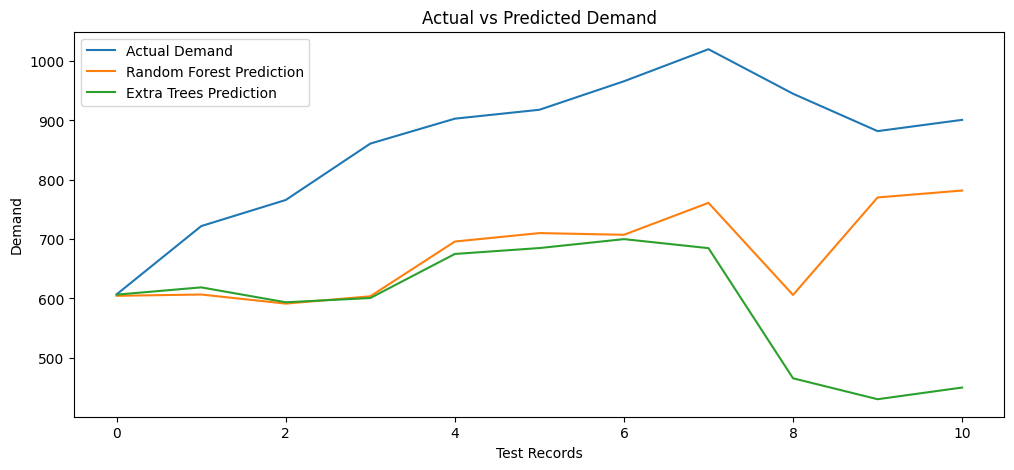

In [35]:
# Comparing actual and predicted demand values

plt.figure(figsize=(12,5))

plt.plot(y_test.values, label='Actual Demand')
plt.plot(rf_pred, label='Random Forest Prediction')
plt.plot(et_pred, label='Extra Trees Prediction')

plt.title('Actual vs Predicted Demand')
plt.xlabel('Test Records')
plt.ylabel('Demand')

plt.legend()
plt.show()

,Feature,Importance
6,Rolling_Mean,0.318031
3,Lag1,0.243430
2,Month,0.163610
0,Day,0.119249
1,Weekday,0.057497
4,Lag2,0.057396
5,Lag7,0.040787


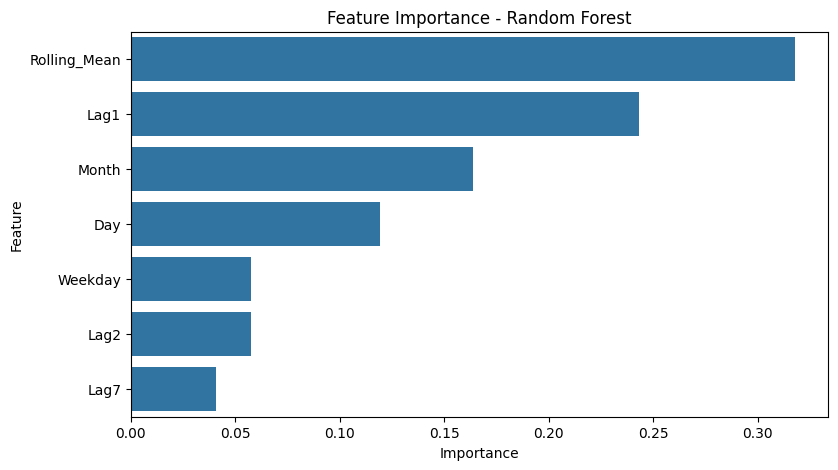

In [36]:
# Extracting feature importance from Random Forest
importance = rf_pipeline.named_steps['model'].feature_importances_

# Creating feature importance dataframe
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

# Sorting features according to importance
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Displaying feature importance
display(feature_importance)

# Visualizing feature importance
plt.figure(figsize=(9,5))

sns.barplot(data=feature_importance,
            x='Importance', y='Feature')

plt.title('Feature Importance - Random Forest')
plt.show()

In [37]:
# Calculating RMSE for both models
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
et_rmse = np.sqrt(mean_squared_error(y_test, et_pred))

# Selecting the best performing model
if rf_rmse <= et_rmse:
    best_model = rf_pipeline
    print("Random Forest is the Best Model")
else:
    best_model = et_pipeline
    print("Extra Trees is the Best Model")

Random Forest is the Best Model


In [38]:
# Creating historical demand series
history = daily.set_index('Date')['Demand'].copy()

# Creating an empty list to store future predictions
forecast = []

# Predicting demand for the next 7 days
for i in range(7):

    # Getting the next date
    next_date = history.index[-1] + pd.Timedelta(days=1)

    # Creating input features for prediction
    new_data = pd.DataFrame([{
        'Day': next_date.day,
        'Weekday': next_date.dayofweek,
        'Month': next_date.month,
        'Lag1': history.iloc[-1],
        'Lag2': history.iloc[-2],
        'Lag7': history.iloc[-7],
        'Rolling_Mean': history.iloc[-7:].mean()
    }])

    # Predicting future demand
    prediction = best_model.predict(new_data)[0]

    # Avoiding negative demand predictions
    prediction = max(0, prediction)

    # Storing forecast results
    forecast.append([next_date, prediction])

    # Updating historical data for next prediction
    history.loc[next_date] = prediction

# Creating forecast dataframe
forecast_df = pd.DataFrame(
    forecast,
    columns=['Date', 'Predicted Demand']
)

# Displaying future demand predictions
display(forecast_df)

,Date,Predicted Demand
0,2022-06-01,746.255
1,2022-06-02,683.945
2,2022-06-03,508.475
3,2022-06-04,597.345
4,2022-06-05,604.505
5,2022-06-06,710.865
6,2022-06-07,735.125


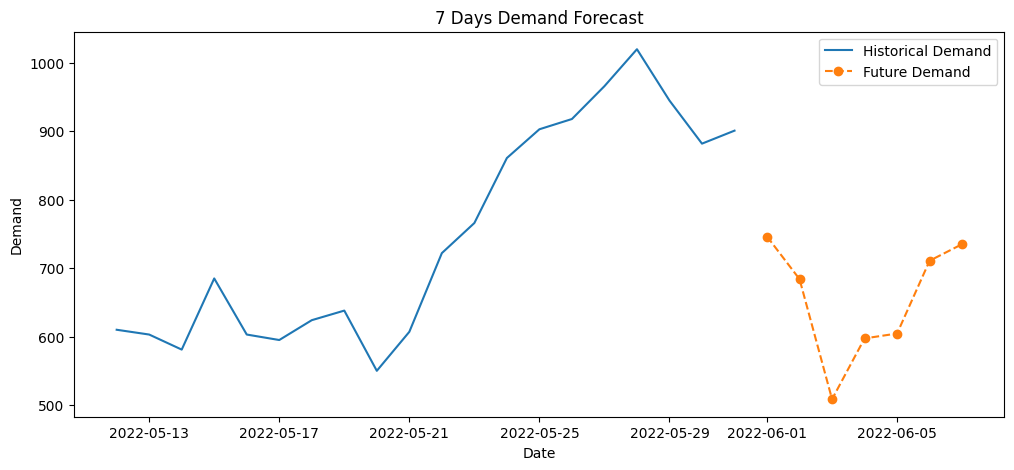

In [39]:
# Visualizing historical and future demand

plt.figure(figsize=(12,5))

plt.plot(daily['Date'].tail(20),
         daily['Demand'].tail(20),
         label='Historical Demand')

plt.plot(forecast_df['Date'],
         forecast_df['Predicted Demand'],
         marker='o',
         linestyle='--',
         label='Future Demand')

plt.title('7 Days Demand Forecast')
plt.xlabel('Date')
plt.ylabel('Demand')

plt.legend()
plt.show()

In [40]:
# Importing joblib for model saving
import joblib

# Saving the trained machine learning model
joblib.dump(best_model, 'G35_Demand_Model.pkl')

# Saving future demand predictions
forecast_df.to_csv('G35_Forecast.csv', index=False)

# Saving cleaned daily demand dataset
daily.to_csv('G35_Cleaned_Data.csv', index=False)

# Saving model evaluation results
results = pd.DataFrame({
    'Model': ['Random Forest', 'Extra Trees'],
    'RMSE': [rf_rmse, et_rmse]
})

results.to_csv('G35_Model_Results.csv', index=False)

print("All Project Files Saved Successfully")

All Project Files Saved Successfully


In [41]:
# Importing Colab file download utility
from google.colab import files

# Downloading trained model
files.download('G35_Demand_Model.pkl')

# Downloading forecast results
files.download('G35_Forecast.csv')

# Downloading cleaned dataset
files.download('G35_Cleaned_Data.csv')

# Downloading model evaluation results
files.download('G35_Model_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>